# AstroDetect · 01 · Explore → Preprocess (step by step, with plots) → Build → Train
**Input:** your dataset `exoplanetdatahuggingface` (folders `raw_0000…raw_0007`, `jobs.json`, CSVs).
**Settings:** Accelerator *None* is fine (GPU optional) · Internet *On* (only for `pip install`).

| Part | What happens | Time |
|---|---|---|
| A | Check the dataset is loaded, set up paths | 1 min |
| B | Dataset overview charts | 1 min |
| C | Every preprocessing / pipeline step on ONE real star, one plot per step (saved to `figures/`) | 3–5 min |
| D | Run the pipeline on all ~750 stars → training samples (auto-retry, resumable) | ~3 h |
| E | Train the CNN, checkpoint **every epoch**, auto-retry + resume | 30–60 min |
| F | Evaluate on unseen stars, export models, zip everything for download | 2 min |

Run parts A–C interactively to look at the plots. For D–F use **Save Version → Save & Run All (Commit)**. If a commit dies, add its output as an input and commit again: finished stars and epochs are skipped.

In [1]:
# CELL 0 - the AstroDetect code, embedded (no dataset upload needed)
# Just run it. If an 'astrodetect-code' dataset is attached, that copy is used instead.
ASTRODETECT_ZIP_B64 = '...'

In [2]:
# A1 - install + load the AstroDetect code (the copy embedded in CELL 0 is always used,
#      so an old code/ folder inside the dataset can't cause version mismatches)
!pip install -q batman-package lightgbm
import os, sys, glob, json, time, shutil, zipfile, base64, io, re, collections, warnings
warnings.filterwarnings('ignore')
CODE = '/kaggle/working/code'
shutil.rmtree(CODE, ignore_errors=True)
zipfile.ZipFile(io.BytesIO(base64.b64decode(ASTRODETECT_ZIP_B64))).extractall(CODE)
sys.path.insert(0, CODE)
for m in [m for m in sys.modules if m.startswith('astrodetect')]:
    del sys.modules[m]
import astrodetect
print('astrodetect', astrodetect.__version__, 'loaded from', astrodetect.__file__)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 9})

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 9.3 MB/s eta 0:00:00
astrodetect 0.1.0 loaded from /kaggle/working/code/astrodetect/__init__.py


In [3]:
# A2 - find the dataset and set every path used below
jobs_hits = glob.glob('/kaggle/input/**/jobs.json', recursive=True)
assert jobs_hits, ('jobs.json not found. Right panel -> Add Input -> Your Work/Datasets -> '
                   'exoplanetdatahuggingface')
DATA    = os.path.dirname(jobs_hits[0])                  # dataset root
RAW     = '/tmp/raw'                                     # TIC_<id>/<file>.fits (symlinks)
OUT     = '/kaggle/working'
FIG     = f'{OUT}/figures'                               # every plot is saved here
SHARDS  = f'{OUT}/shards'                                # training samples
CKPT    = f'{OUT}/checkpoints'                           # one file per epoch
MODELS  = f'{OUT}/models'                                # final models for detection
for d in (RAW, FIG, SHARDS, CKPT, MODELS):
    os.makedirs(d, exist_ok=True)
print('DATA =', DATA)
for name in sorted(os.listdir(DATA)):
    p = os.path.join(DATA, name)
    n = sum(len(f) for _, _, f in os.walk(p)) if os.path.isdir(p) else 1
    print(f'  {name:20s} {"dir " if os.path.isdir(p) else "file"}  {n} file(s)')

DATA = /kaggle/input/datasets/teextc30anshkini/exoplanetdatahuggingface
  code                 dir   14 file(s)
  jobs.json            file  1 file(s)
  lightcurves.csv      file  1 file(s)
  raw_0000             dir   264 file(s)
  raw_0001             dir   288 file(s)
  raw_0002             dir   326 file(s)
  raw_0003             dir   289 file(s)
  raw_0004             dir   282 file(s)
  raw_0005             dir   276 file(s)
  raw_0006             dir   269 file(s)
  raw_0007             dir   118 file(s)
  signals.csv          file  1 file(s)
  targets.csv          file  1 file(s)


In [4]:
# A3 - index every light-curve file (works whether raw_XXXX are tars or unpacked folders)
import tarfile
for t in glob.glob(f'{DATA}/**/raw_*.tar', recursive=True):
    tarfile.open(t).extractall(RAW)
n = 0
for f in glob.glob(f'{DATA}/**/*.fits', recursive=True):
    name, parent = os.path.basename(f), os.path.basename(os.path.dirname(f))
    if parent.startswith('TIC_'):
        tic_dir = parent
    else:
        m = re.search(r'-(\d{16})-', name)
        if not m: continue
        tic_dir = f'TIC_{int(m.group(1))}'
    dst = f'{RAW}/{tic_dir}/{name}'
    if not os.path.exists(dst):
        os.makedirs(os.path.dirname(dst), exist_ok=True); os.symlink(f, dst); n += 1
on_disk = {d for d in os.listdir(RAW) if d.startswith('TIC_')}
jobs = [j for j in json.load(open(jobs_hits[0])) if f"TIC_{j['tic']}" in on_disk]
JOBS_FILE = '/tmp/jobs_on_disk.json'; json.dump(jobs, open(JOBS_FILE, 'w'))
signals = pd.read_csv(f'{DATA}/signals.csv'); targets = pd.read_csv(f'{DATA}/targets.csv')
print(f'{n} FITS files linked | {len(on_disk)} stars on disk | {len(jobs)} stars in the job list')
assert len(jobs) > 0, 'dataset is attached but no light curves were found'
print('DATASET LOADED OK')

2112 FITS files linked | 745 stars on disk | 745 stars in the job list
DATASET LOADED OK


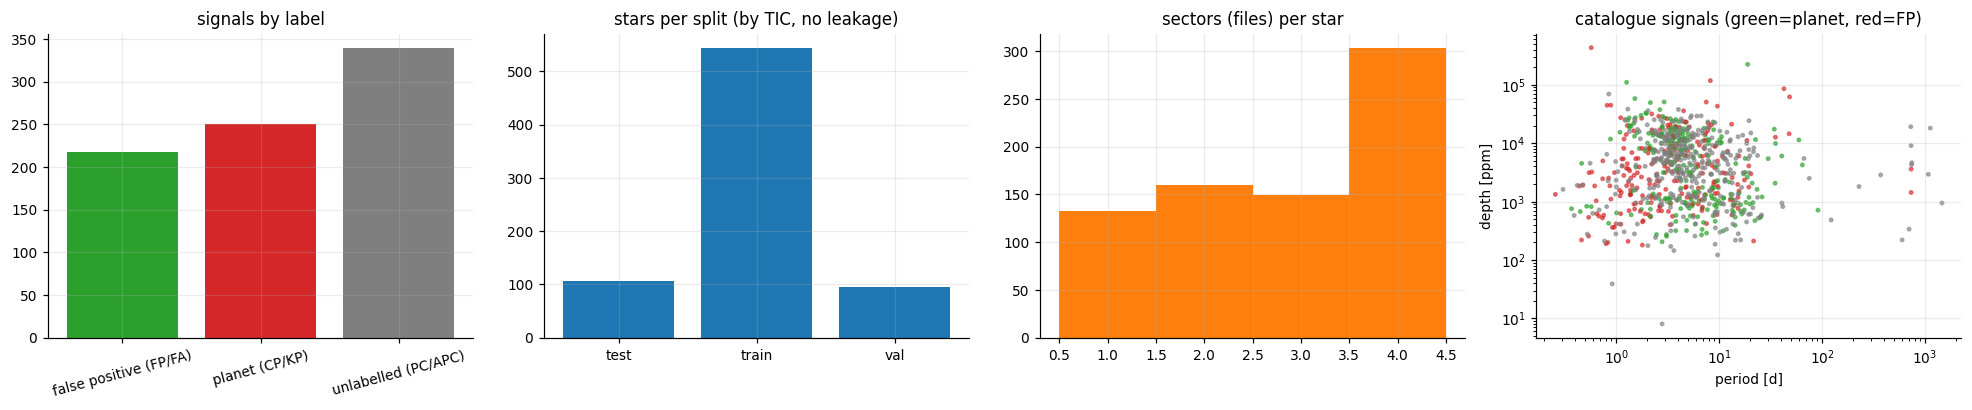

{'false positive (FP/FA)': 218, 'planet (CP/KP)': 250, 'unlabelled (PC/APC)': 339} {'test': 107, 'train': 543, 'val': 95}


In [5]:
# B1 - dataset overview
LAB = {0: 'planet (CP/KP)', -2: 'false positive (FP/FA)', -1: 'unlabelled (PC/APC)'}
lab = collections.Counter(LAB[s['label']] for j in jobs for s in j['signals'])
spl = collections.Counter(j['split'] for j in jobs)
nfiles = [len(j['files']) for j in jobs]
per = [s['period'] for j in jobs for s in j['signals']]
dep = [s['depth'] * 1e6 for j in jobs for s in j['signals']]
col = [{0: 'C2', -2: 'C3', -1: 'C7'}[s['label']] for j in jobs for s in j['signals']]
fig, ax = plt.subplots(1, 4, figsize=(18, 3.8))
ax[0].bar(lab.keys(), lab.values(), color=['C2', 'C3', 'C7'][:len(lab)]); ax[0].set_title('signals by label')
ax[0].tick_params(axis='x', rotation=15)
ax[1].bar(spl.keys(), spl.values(), color='C0'); ax[1].set_title('stars per split (by TIC, no leakage)')
ax[2].hist(nfiles, bins=np.arange(0.5, max(nfiles) + 1.5), color='C1'); ax[2].set_title('sectors (files) per star')
ax[3].scatter(per, dep, s=5, c=col, alpha=.6); ax[3].set_xscale('log'); ax[3].set_yscale('log')
ax[3].set_xlabel('period [d]'); ax[3].set_ylabel('depth [ppm]'); ax[3].set_title('catalogue signals (green=planet, red=FP)')
plt.tight_layout(); plt.savefig(f'{FIG}/B1_dataset_overview.png'); plt.show()
print(dict(lab), dict(spl))

## Part C · The pipeline on one real star, step by step
Every figure below is also saved in `figures/` for slides. Set `EXAMPLE_TIC` to show a different star.

In [6]:
# C1 - pick an example: a confirmed planet with a clear transit (or set EXAMPLE_TIC yourself)
EXAMPLE_TIC = None
from astrodetect.io import read_lc
from astrodetect.pipeline import load_star
if EXAMPLE_TIC is None:
    cands = [(j, s) for j in jobs for s in j['signals']
             if s['label'] == 0 and 1500 < s['depth'] * 1e6 < 30000 and 0.8 < s['period'] < 10]
    cands.sort(key=lambda js: -js[1]['depth'])
    job, SIG = cands[len(cands) // 3] if cands else (jobs[0], jobs[0]['signals'][0])
else:
    job = next(j for j in jobs if j['tic'] == EXAMPLE_TIC); SIG = job['signals'][0]
PATHS = sorted(glob.glob(f"{RAW}/TIC_{job['tic']}/*.fits"))[:2]
print(f"TIC {job['tic']} | {SIG['uid']} | label {LAB[SIG['label']]} | P = {SIG['period']:.4f} d | "
      f"depth {SIG['depth']*1e6:.0f} ppm | duration {SIG['duration']*24:.2f} h | {len(PATHS)} file(s)")

TIC 188570092 | TOI:294.01 | label planet (CP/KP) | P = 7.3279 d | depth 13710 ppm | duration 2.90 h | 2 file(s)


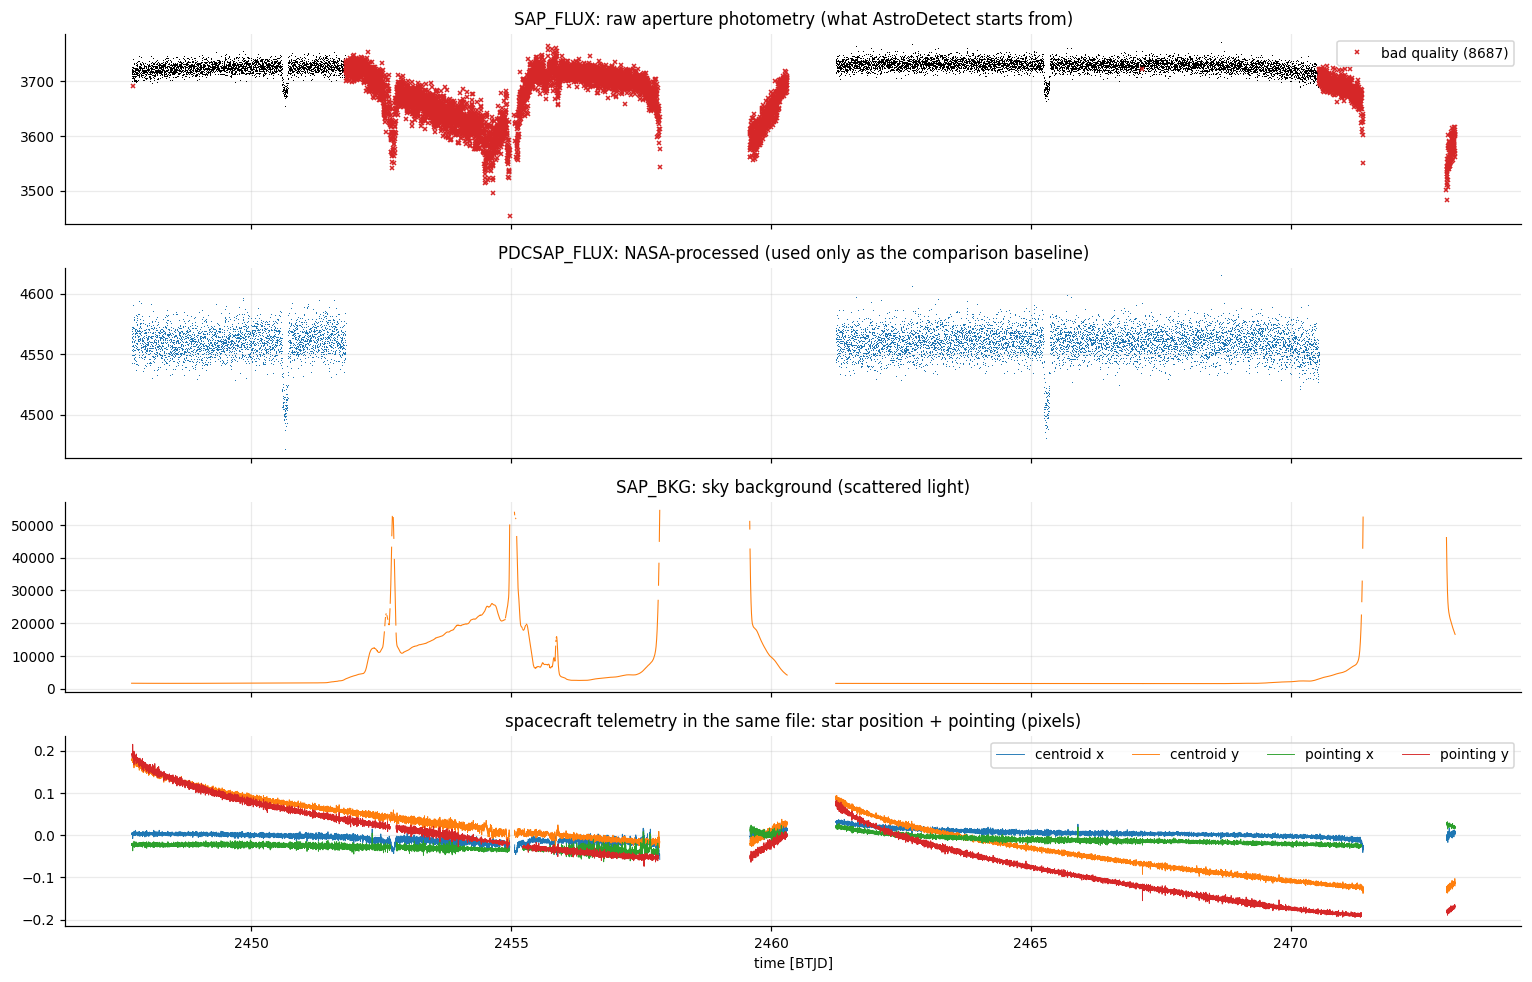

CROWDSAP = 0.99929285  (fraction of aperture flux that belongs to this star)


In [7]:
# C2 - STEP 0: what is inside a raw lc.fits file
from astropy.io import fits
with fits.open(PATHS[0]) as h:
    d, hdr = h[1].data, h[1].header
    t, sap, pdc, q = d['TIME'], d['SAP_FLUX'], d['PDCSAP_FLUX'], d['QUALITY']
    bkg, cx, cy = d['SAP_BKG'], d['MOM_CENTR1'], d['MOM_CENTR2']
    px, py = d['POS_CORR1'], d['POS_CORR2']
bad = (q != 0) | ~np.isfinite(sap)
fig, ax = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
ax[0].plot(t[~bad], sap[~bad], ',', color='k'); ax[0].plot(t[bad], sap[bad], 'x', ms=3, color='C3', label=f'bad quality ({bad.sum()})')
ax[0].set_title('SAP_FLUX: raw aperture photometry (what AstroDetect starts from)'); ax[0].legend()
ax[1].plot(t, pdc, ',', color='C0'); ax[1].set_title('PDCSAP_FLUX: NASA-processed (used only as the comparison baseline)')
ax[2].plot(t, bkg, color='C1', lw=.7); ax[2].set_title('SAP_BKG: sky background (scattered light)')
ax[3].plot(t, cx - np.nanmedian(cx), lw=.6, label='centroid x'); ax[3].plot(t, cy - np.nanmedian(cy), lw=.6, label='centroid y')
ax[3].plot(t, px, lw=.6, label='pointing x'); ax[3].plot(t, py, lw=.6, label='pointing y')
ax[3].set_title('spacecraft telemetry in the same file: star position + pointing (pixels)'); ax[3].legend(ncol=4)
ax[3].set_xlabel('time [BTJD]'); plt.tight_layout(); plt.savefig(f'{FIG}/C2_raw_file_contents.png'); plt.show()
print(f"CROWDSAP = {hdr.get('CROWDSAP')}  (fraction of aperture flux that belongs to this star)")

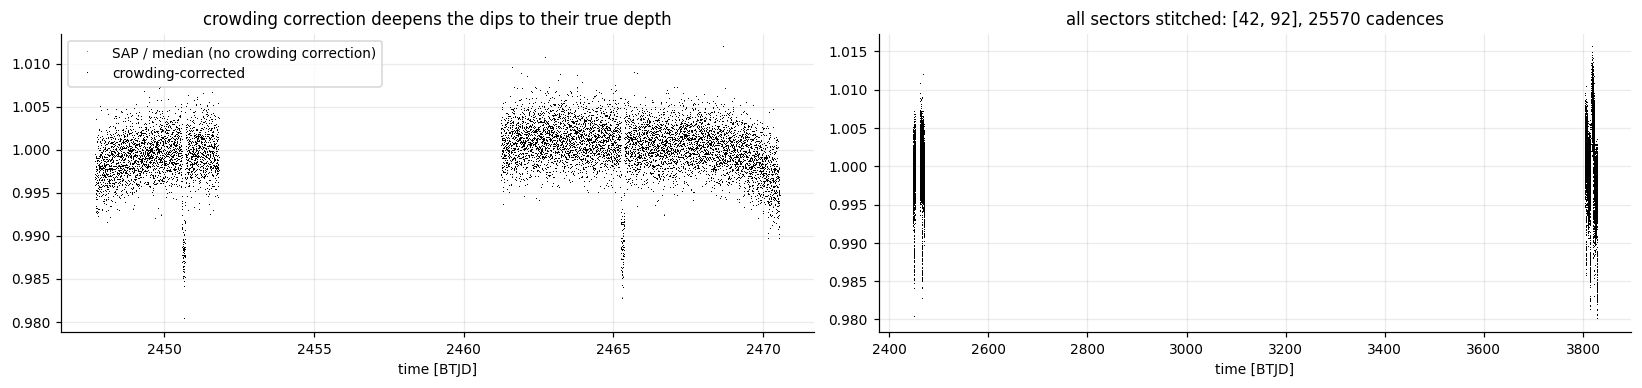

In [8]:
# C3 - STEP 1: quality mask, crowding correction, normalisation, stitching sectors
lc = load_star(PATHS)
raw_norm = sap[~bad] / np.nanmedian(sap[~bad])
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
ax[0].plot(t[~bad], raw_norm, ',', color='0.5', label='SAP / median (no crowding correction)')
m = lc.sector == lc.sector[0]
ax[0].plot(lc.time[m], lc.sap[m], ',', color='k', label='crowding-corrected')
ax[0].set_title('crowding correction deepens the dips to their true depth'); ax[0].legend(markerscale=20)
ax[1].plot(lc.time, lc.sap, ',', color='k'); ax[1].set_title(f'all sectors stitched: {lc.meta["sectors"]}, {len(lc)} cadences')
for a in ax: a.set_xlabel('time [BTJD]')
plt.tight_layout(); plt.savefig(f'{FIG}/C3_clean_crowding_stitch.png'); plt.show()

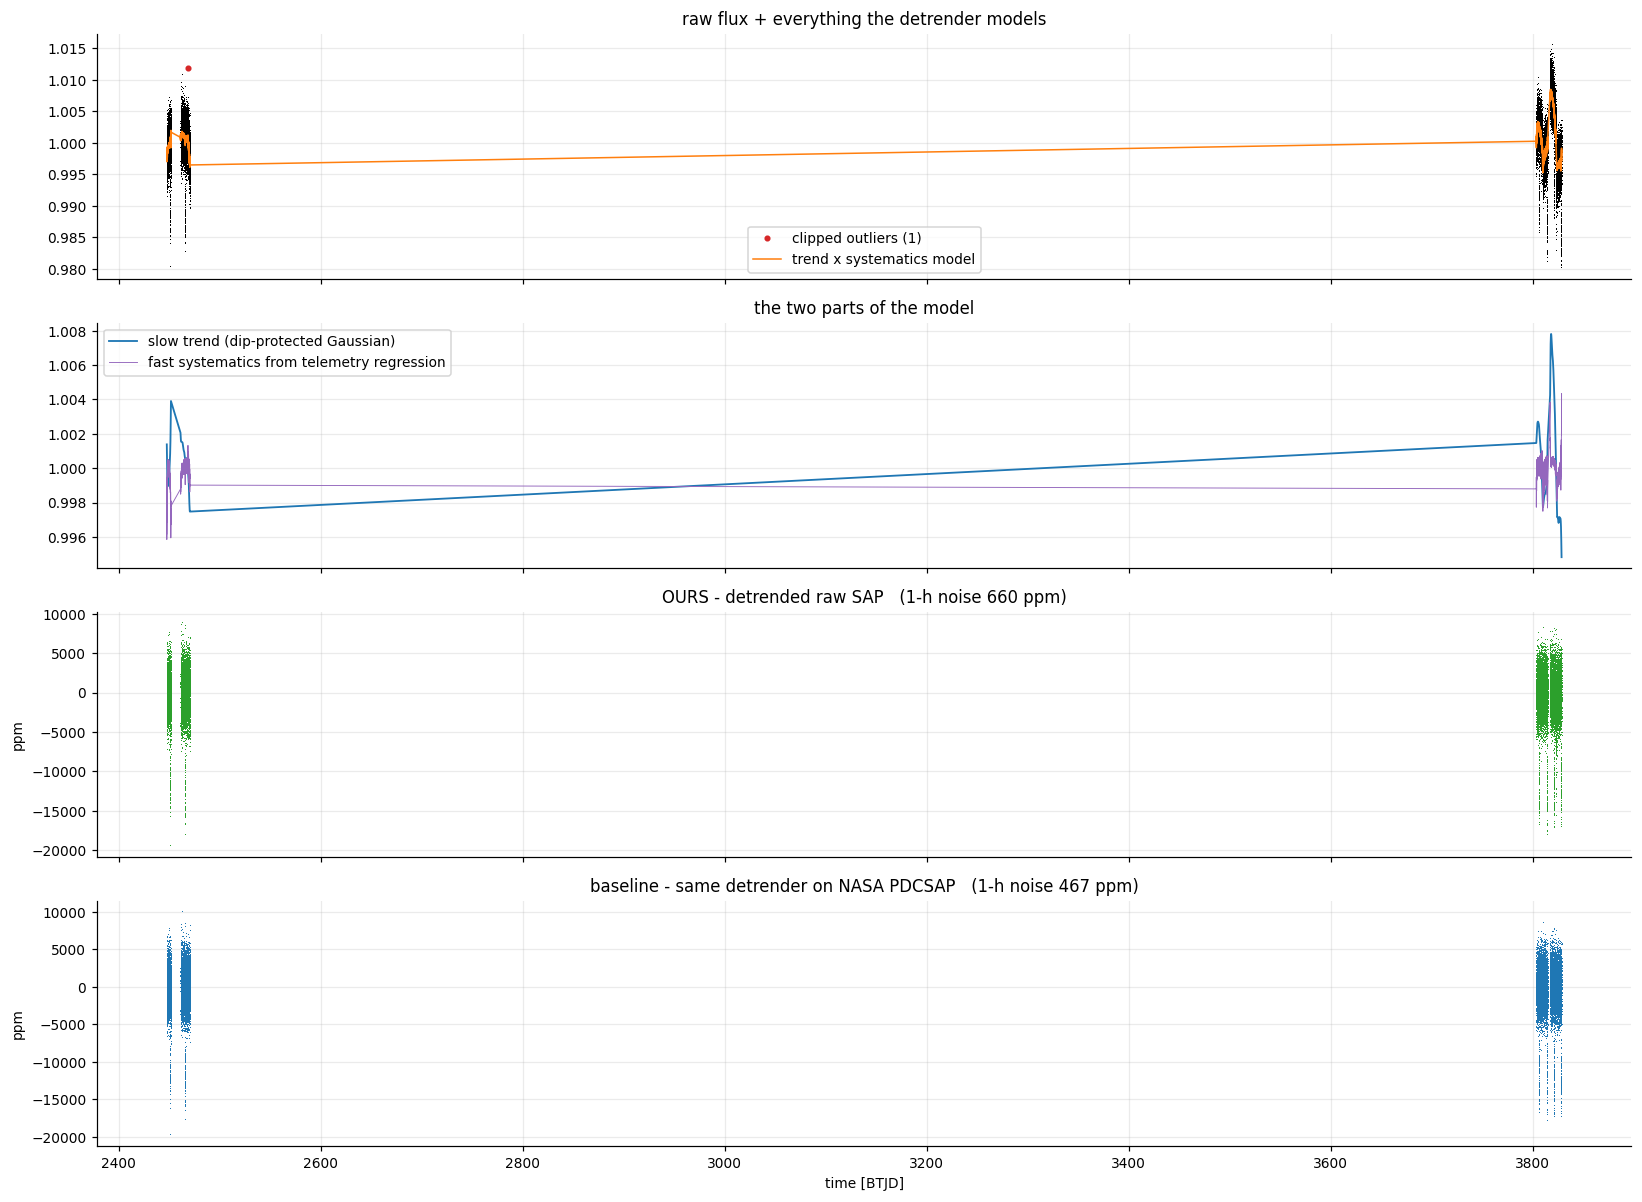

In [9]:
# C4 - STEP 2: detrending (novel) = robust trend + telemetry regression, vs NASA PDCSAP
from astrodetect.detrend import detrend_raw, detrend_pdc, clip_upper_outliers
from astrodetect.metrics_lite import cdpp
from astrodetect.search import transit_mask
D_raw, D_pdc = detrend_raw(lc), detrend_pdc(lc)
keep = D_raw['keep']
oot = ~transit_mask(lc.time, SIG['period'], SIG['t0'], max(SIG['duration'], .04), 1.5)   # noise measured out of transit
noise = lambda f: cdpp(lc.time[oot], f[oot])
fig, ax = plt.subplots(4, 1, figsize=(15, 11), sharex=True)
ax[0].plot(lc.time, lc.sap, ',', color='k')
ax[0].plot(lc.time[~keep], lc.sap[~keep], 'o', ms=3, color='C3', label=f'clipped outliers ({(~keep).sum()})')
ax[0].plot(lc.time, D_raw['trend'] * D_raw['systematics'], color='C1', lw=1, label='trend x systematics model')
ax[0].set_title('raw flux + everything the detrender models'); ax[0].legend()
ax[1].plot(lc.time, D_raw['trend'], color='C0', lw=1.2, label='slow trend (dip-protected Gaussian)')
ax[1].plot(lc.time, D_raw['systematics'], color='C4', lw=.6, label='fast systematics from telemetry regression')
ax[1].set_title('the two parts of the model'); ax[1].legend()
ax[2].plot(lc.time, (D_raw['flux'] - 1) * 1e6, ',', color='C2')
ax[2].set_title(f'OURS - detrended raw SAP   (1-h noise {noise(D_raw["flux"]):.0f} ppm)')
ax[3].plot(lc.time, (D_pdc['flux'] - 1) * 1e6, ',', color='C0')
ax[3].set_title(f'baseline - same detrender on NASA PDCSAP   (1-h noise {noise(D_pdc["flux"]):.0f} ppm)')
for a in ax[2:]: a.set_ylabel('ppm')
ax[3].set_xlabel('time [BTJD]'); plt.tight_layout(); plt.savefig(f'{FIG}/C4_detrending.png'); plt.show()

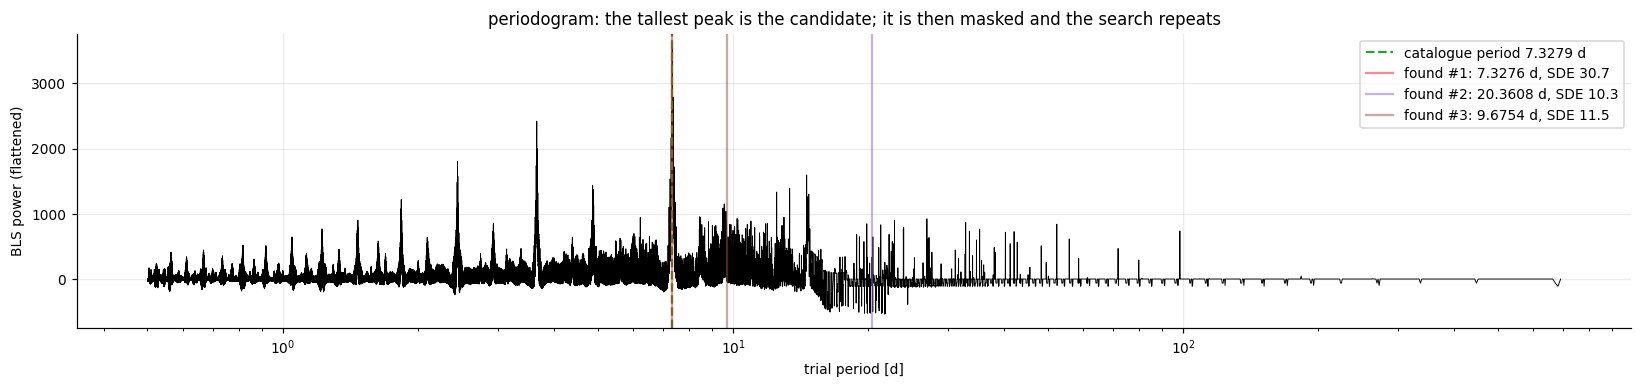

catalogue signal recovered by our search: True


In [10]:
# C5 - STEP 3: identification - iterative Box Least Squares search
from astrodetect.search import iterative_search, matches
cands = iterative_search(lc.time, D_raw['flux'], max_cands=3, keep_periodogram=True)
fig, ax = plt.subplots(1, 1, figsize=(15, 3.6))
ax.plot(cands[0]['periods'], cands[0]['power'], lw=.6, color='k')
ax.axvline(SIG['period'], color='C2', ls='--', label=f'catalogue period {SIG["period"]:.4f} d')
for i, c in enumerate(cands):
    ax.axvline(c['period'], color=f'C{i+3}', alpha=.5, label=f'found #{i+1}: {c["period"]:.4f} d, SDE {c["sde"]:.1f}')
ax.set_xscale('log'); ax.set_xlabel('trial period [d]'); ax.set_ylabel('BLS power (flattened)')
ax.set_title('periodogram: the tallest peak is the candidate; it is then masked and the search repeats'); ax.legend()
plt.tight_layout(); plt.savefig(f'{FIG}/C5_bls_search.png'); plt.show()
hit = next((c for c in cands if matches(c['period'], SIG['period'])), None)
CAND = hit or dict(period=SIG['period'], t0=SIG['t0'], duration=SIG['duration'], depth=SIG['depth'], sde=0)
print('catalogue signal recovered by our search:', hit is not None)

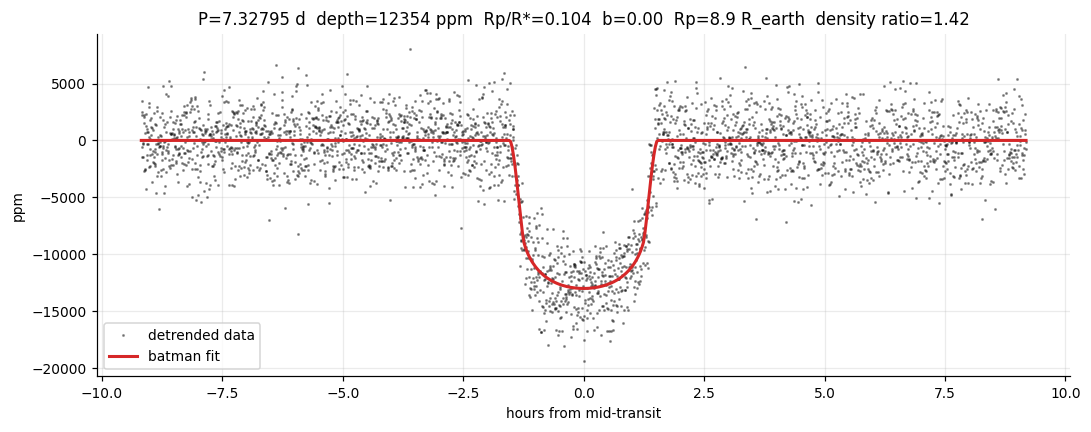

In [11]:
# C6 - STEP 4: characterization - batman transit fit (masked re-detrend first)
from astrodetect.pipeline import analyse_candidate
from astrodetect.characterize import _model, limb_darkening
from astrodetect.vetting import phase
A = analyse_candidate(lc, CAND, 'raw'); F, DG = A['fit'], A['diag']
ph = phase(lc.time, F['period'], F['t0']) * 24
near = np.abs(ph) < 3 * F['duration'] * 24
tt = np.linspace(-3 * F['duration'], 3 * F['duration'], 600)
mod = _model([0, F['period'], F['rp_rs'], F['a_rs'], F['b']], tt, limb_darkening(lc.meta.get('teff')), 0)
fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(ph[near], (A['flux'][near] - 1) * 1e6, '.', ms=2, alpha=.35, color='k', label='detrended data')
ax.plot(tt * 24, (mod - 1) * 1e6, color='C3', lw=2, label='batman fit')
ax.set_xlabel('hours from mid-transit'); ax.set_ylabel('ppm'); ax.legend()
ax.set_title(f"P={F['period']:.5f} d  depth={DG['depth_ppm']:.0f} ppm  Rp/R*={F['rp_rs']:.3f}  b={F['b']:.2f}  "
             f"Rp={F['rp_earth']:.1f} R_earth  density ratio={F['rho_ratio']:.2f}")
plt.tight_layout(); plt.savefig(f'{FIG}/C6_transit_fit.png'); plt.show()

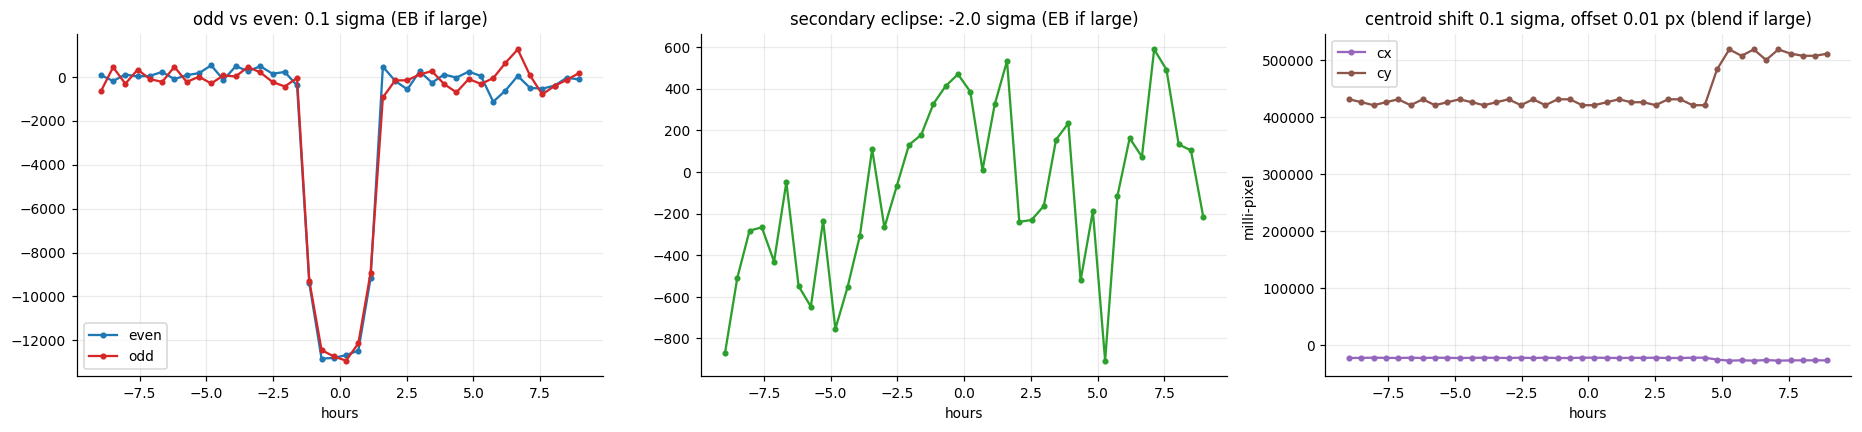

depth_ppm              12354.117
snr                       56.611
n_transits                 6.000
beta_flux                  2.278
odd_even_sigma             0.096
secondary_depth_ppm     -587.884
secondary_sigma           -2.025
v_shape                    0.812
cx_shift_sigma             0.109
cx_shift_px                0.000
cy_shift_sigma            -0.067
cy_shift_px               -0.000
centroid_sigma             0.128
source_offset_px           0.011
bkg_shift_sigma            0.160
max_event_fraction         0.175
sector_depth_chi2          7.380
dtype: float64

In [12]:
# C7 - STEP 5: vetting diagnostics (EB and blend tests from the light-curve file alone)
ep = np.round((lc.time - F['t0']) / F['period']).astype(int)
ph2 = (((lc.time - F['t0']) % F['period']) - F['period'] / 2) * 24
w = 3 * F['duration'] * 24
def binned(x, y, n=40):
    e = np.linspace(-w, w, n + 1); i = np.digitize(x, e) - 1
    return 0.5 * (e[1:] + e[:-1]), np.array([np.nanmean(y[i == k]) if (i == k).any() else np.nan for k in range(n)])
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for k, c, name in ((0, 'C0', 'even'), (1, 'C3', 'odd')):
    m = near & (ep % 2 == k); x, y = binned(ph[m], (A['flux'][m] - 1) * 1e6)
    ax[0].plot(x, y, 'o-', ms=3, color=c, label=name)
ax[0].set_title(f"odd vs even: {DG['odd_even_sigma']:.1f} sigma (EB if large)"); ax[0].legend()
m2 = np.abs(ph2) < w; x, y = binned(ph2[m2], (A['flux'][m2] - 1) * 1e6)
ax[1].plot(x, y, 'o-', ms=3, color='C2'); ax[1].set_title(f"secondary eclipse: {DG['secondary_sigma']:.1f} sigma (EB if large)")
for key, c in (('cx', 'C4'), ('cy', 'C5')):
    cc = lc.aux[key] - np.nanmedian(lc.aux[key][near]); x, y = binned(ph[near], cc[near] * 1e3)
    ax[2].plot(x, y, 'o-', ms=3, color=c, label=key)
ax[2].set_title(f"centroid shift {DG['centroid_sigma']:.1f} sigma, offset {DG['source_offset_px']:.2f} px (blend if large)")
ax[2].set_ylabel('milli-pixel'); ax[2].legend()
for a in ax: a.set_xlabel('hours')
plt.tight_layout(); plt.savefig(f'{FIG}/C7_vetting.png'); plt.show()
pd.Series(DG).round(3)

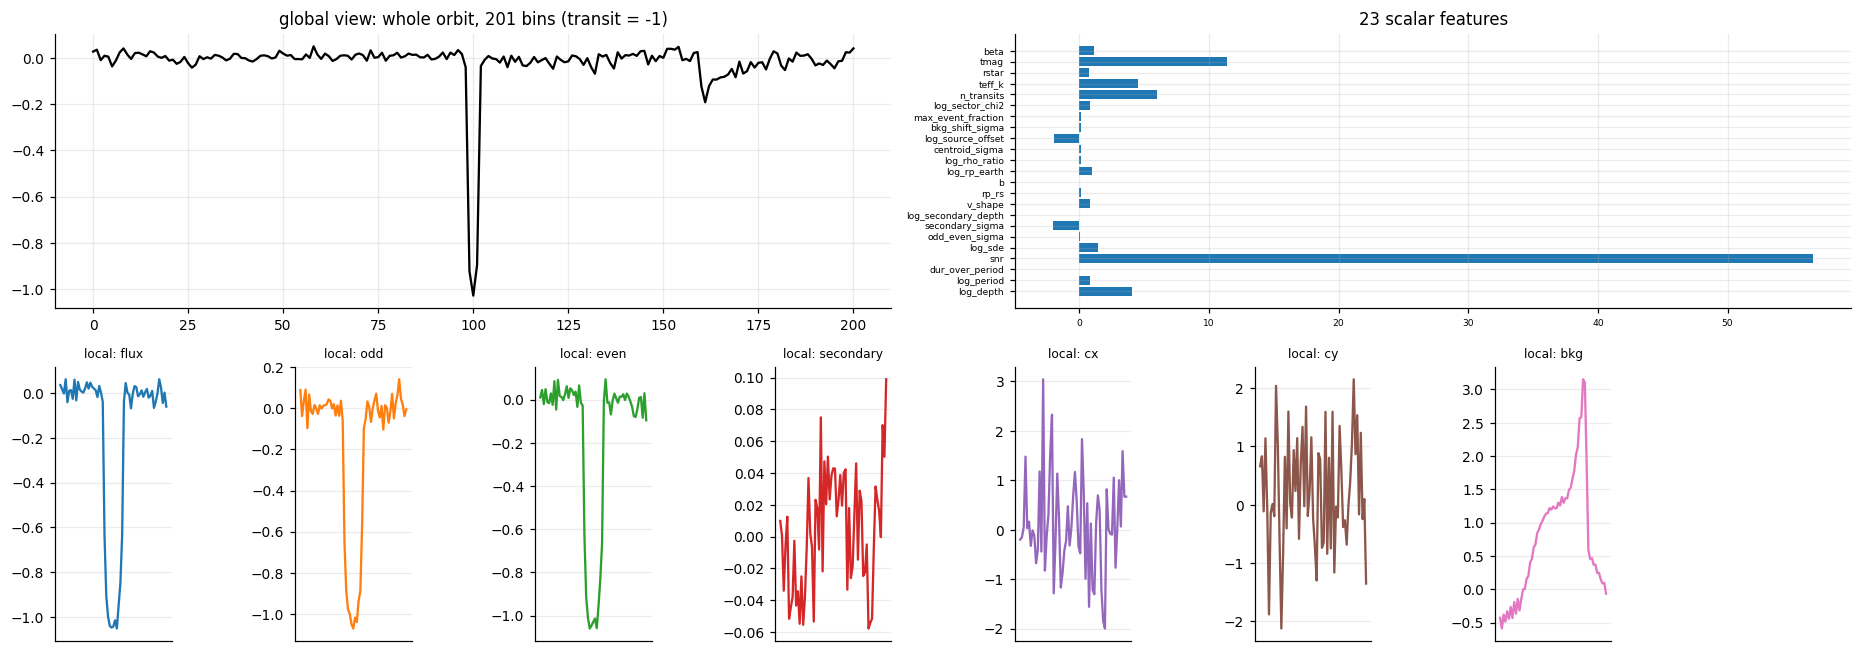

In [13]:
# C8 - STEP 6: what the CNN actually sees (views + scalar features)
from astrodetect.views import LOCAL_CHANNELS, SCALARS
fig = plt.figure(figsize=(17, 6)); gs = fig.add_gridspec(2, 8)
a = fig.add_subplot(gs[0, :4]); a.plot(A['g'][0], color='k'); a.set_title('global view: whole orbit, 201 bins (transit = -1)')
a = fig.add_subplot(gs[0, 4:]); a.barh(SCALARS, A['s'], color='C0'); a.set_title('23 scalar features'); a.tick_params(labelsize=6)
for i, name in enumerate(LOCAL_CHANNELS):
    a = fig.add_subplot(gs[1, i]); a.plot(A['l'][i], color=f'C{i}'); a.set_title(f'local: {name}', fontsize=8); a.set_xticks([])
plt.tight_layout(); plt.savefig(f'{FIG}/C8_model_inputs.png'); plt.show()

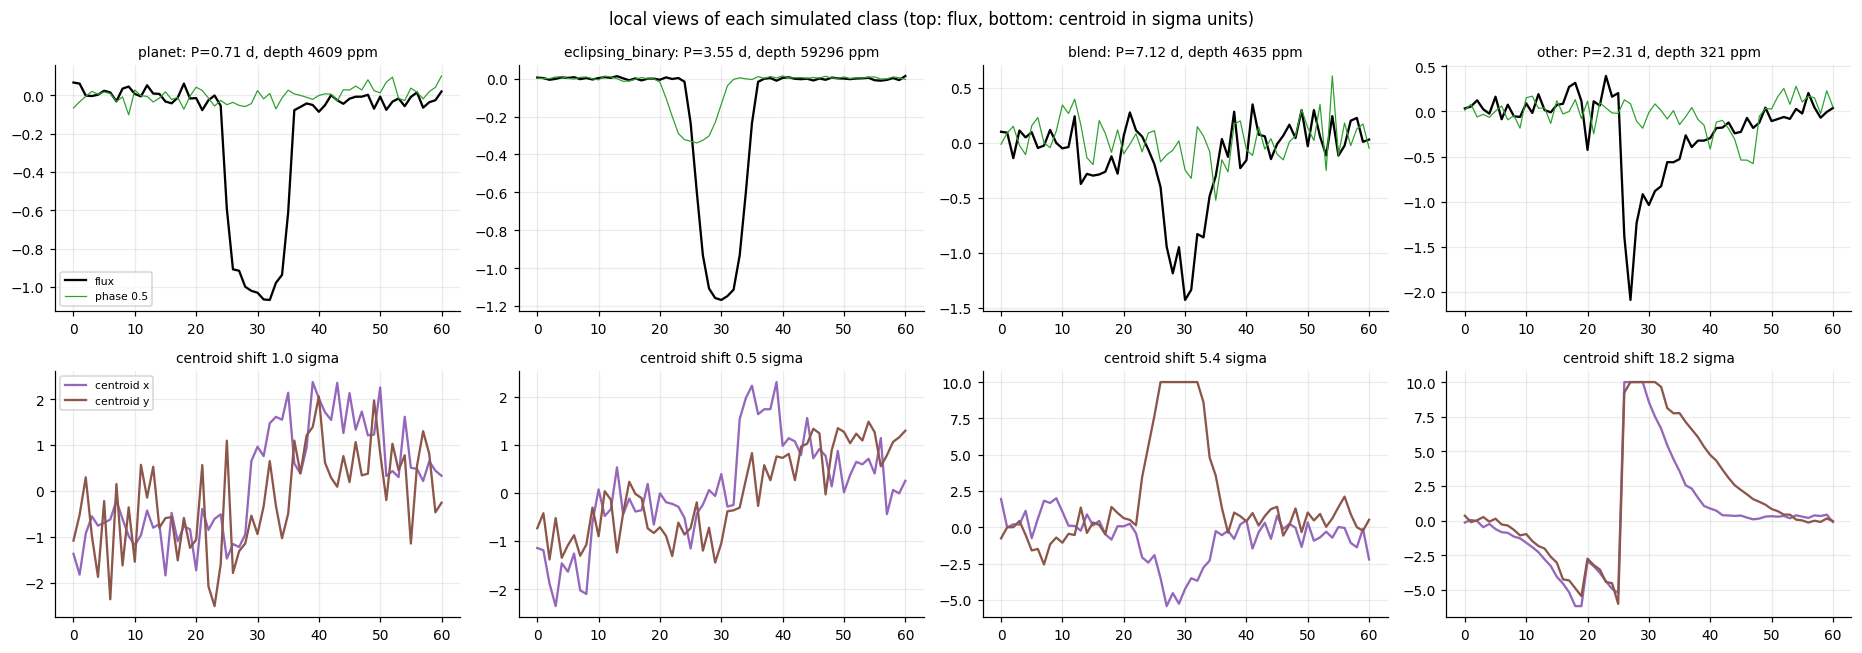

In [14]:
# C9 - STEP 7: physics simulations injected into THIS star's real noise (the 4 training classes)
from astrodetect.simulate import inject, CLASSES
from astrodetect.search import transit_mask
bg = lc.select(~transit_mask(lc.time, SIG['period'], SIG['t0'], max(SIG['duration'], .04), 2.5))
rng = np.random.default_rng(3)
fig, ax = plt.subplots(2, 4, figsize=(17, 6))
for k, cls in enumerate(CLASSES):
    for attempt in range(6):                                  # retry until the search finds it
        sim, truth = inject(bg, cls, rng)
        sd = detrend_raw(sim); sc = iterative_search(sim.time, sd['flux'], max_cands=2, pmax=30)
        hit = sc[0] if cls == 'other' else next((c for c in sc if matches(c['period'], truth['period'])), None)
        if hit: break
    if not hit:
        ax[0, k].set_title(f'{cls}: not recovered'); continue
    S = analyse_candidate(sim, hit, 'raw')
    ax[0, k].plot(S['l'][0], color='k', label='flux'); ax[0, k].plot(S['l'][3], color='C2', lw=.8, label='phase 0.5')
    ax[0, k].set_title(f"{cls}: P={truth['period']:.2f} d, depth {truth['depth']*1e6:.0f} ppm", fontsize=9)
    ax[1, k].plot(S['l'][4], color='C4', label='centroid x'); ax[1, k].plot(S['l'][5], color='C5', label='centroid y')
    ax[1, k].set_title(f"centroid shift {S['diag']['centroid_sigma']:.1f} sigma", fontsize=9)
ax[0, 0].legend(fontsize=7); ax[1, 0].legend(fontsize=7)
plt.suptitle('local views of each simulated class (top: flux, bottom: centroid in sigma units)')
plt.tight_layout(); plt.savefig(f'{FIG}/C9_simulated_classes.png'); plt.show()

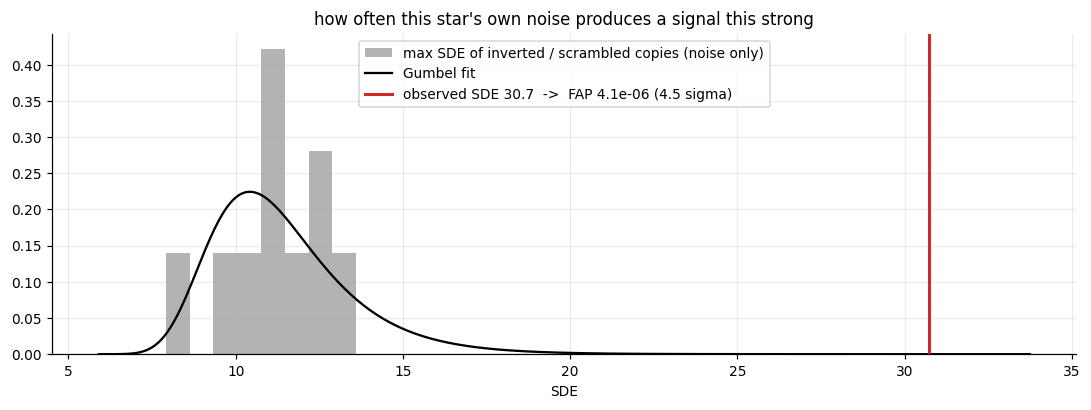

In [15]:
# C10 - STEP 8: statistical significance - empirical false-alarm probability for this star
from astrodetect.significance import null_curves
from astrodetect.search import bin_series, bls_search
from scipy import stats
tb, yb = bin_series(lc.time, D_raw['flux'])
mm = transit_mask(tb, CAND['period'], CAND['t0'], CAND['duration'], 2.0)
tb, yb = tb[~mm], yb[~mm] - np.median(yb[~mm])
null = [r['sde'] for _, tn, yn in null_curves(tb, yb, np.random.default_rng(0), n_scramble=9)
        if (r := bls_search(tn, yn)) is not None]
loc, scale = stats.gumbel_r.fit(null); obs = CAND.get('sde') or DG['snr']
fap = max(stats.gumbel_r.sf(obs, loc, scale), 1e-15)
x = np.linspace(min(null) - 2, max(obs, max(null)) + 3, 300)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.hist(null, bins=8, density=True, color='0.7', label='max SDE of inverted / scrambled copies (noise only)')
ax.plot(x, stats.gumbel_r.pdf(x, loc, scale), color='k', label='Gumbel fit')
ax.axvline(obs, color='C3', lw=2, label=f'observed SDE {obs:.1f}  ->  FAP {fap:.1e} ({stats.norm.isf(fap):.1f} sigma)')
ax.set_xlabel('SDE'); ax.legend(); ax.set_title("how often this star's own noise produces a signal this strong")
plt.tight_layout(); plt.savefig(f'{FIG}/C10_significance.png'); plt.show()

## Part D · Build the training set for all stars (auto-retry, resumable)
Each star: detrend → search → fit → vetting → views, for its catalogue signals + 2 physics simulations, done twice (**raw** = ours, **pdc** = NASA baseline). Quick check: set `N_TEST_STARS = 10` first.

In [16]:
# D1 - build (retries: each star is retried inside the worker; the whole run restarts
#      up to 3 times if the process pool crashes; finished stars are never redone)
from astrodetect.build import run
N_TEST_STARS = None                      # e.g. 10 for a quick check, None = all stars
jf = JOBS_FILE
if N_TEST_STARS:
    jf = '/tmp/jobs_test.json'; json.dump(jobs[:N_TEST_STARS], open(jf, 'w'))
for f in glob.glob('/kaggle/input/**/shards/*', recursive=True):   # resume from a previous commit
    if not os.path.exists(f'{SHARDS}/{os.path.basename(f)}'): shutil.copy(f, SHARDS)
for attempt in range(1, 4):
    try:
        run(SHARDS, workers=4, time_budget_h=7.5, jobs_file=jf, local_root=RAW,
            n_sims=2, n_sims_test=2, max_sectors=2, max_files_per_star=4, shard_size=50)
        break
    except Exception as e:
        print(f'build attempt {attempt} failed: {e!r} - retrying (finished stars are kept)')
        time.sleep(10)
rec = pd.concat([pd.read_csv(f) for f in glob.glob(f'{SHARDS}/*_recovery.csv')])
rec.to_csv(f'{OUT}/recovery_all.csv', index=False)
print(rec.groupby(['kind', 'label'])['recovered'].agg(['mean', 'size']))

745 stars to process (shard 0/1), 0 already done
50 stars, 0.34 h
100 stars, 0.69 h
150 stars, 1.02 h
200 stars, 1.38 h
250 stars, 1.73 h
300 stars, 2.10 h
350 stars, 2.43 h
400 stars, 2.80 h
TIC 1717732429 failed:
, in clip_upper_outliers
    g, idx, cad = to_grid(time[s], flux[s])
                  ^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/kaggle/working/code/astrodetect/detrend.py", line 44, in to_grid
    g = np.full(idx[-1] + 1, np.nan)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/numpy/_core/numeric.py", line 361, in full
    a = empty(shape, dtype, order, device=device)
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
ValueError: negative dimensions are not allowed

450 stars, 3.13 h
500 stars, 3.48 h
550 stars, 3.83 h
600 stars, 4.17 h
650 stars, 4.53 h
700 stars, 4.86 h
finished 745
                mean  size
kind label                
real -2     0.446512   215
     -1     0.544615   325
      0     0.625000   248
sim   0     0.551913   366
 

15 shards, 3586 samples


col_0         EB  blend  other  planet  real FP  unlabelled
row_0 row_1                                                
test  real     0      0      0      66       52         112
      sim     82     40    114      50        0           0
train real     0      0      0     364      324         460
      sim    484    236    462     302        0           0
val   real     0      0      0      66       54          78
      sim     92     42     54      52        0           0

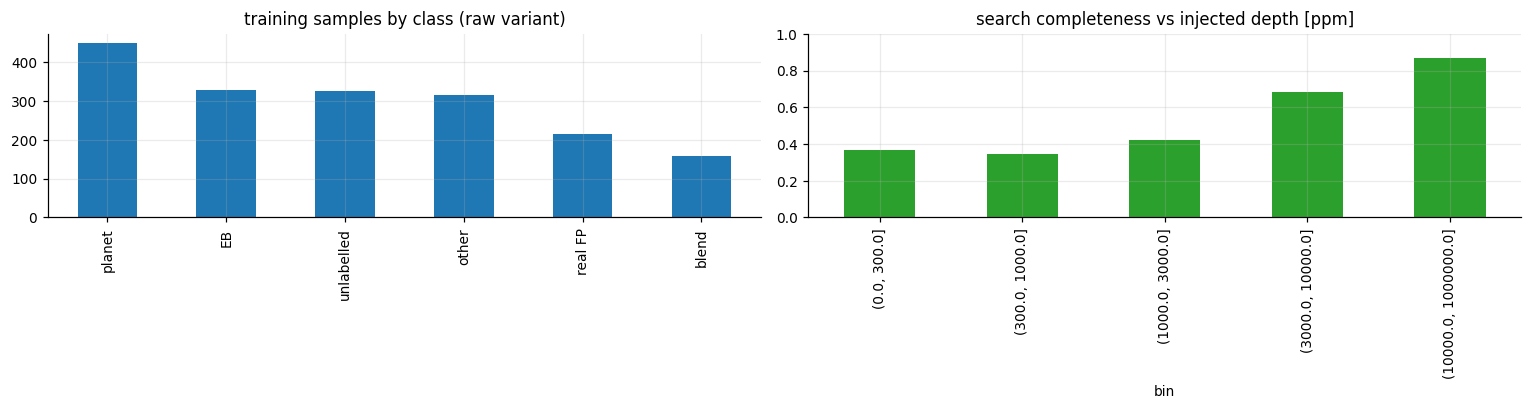

In [17]:
# D2 - what was built
files = sorted(glob.glob(f'{SHARDS}/shard_*.npz'))
parts = [dict(np.load(f)) for f in files]
D = {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}
NAMES = {0: 'planet', 1: 'EB', 2: 'blend', 3: 'other', -2: 'real FP', -1: 'unlabelled'}
tab = pd.crosstab([D['split'], D['kind']], pd.Series(D['y']).map(NAMES)).loc[:, lambda x: x.columns]
print(f'{len(files)} shards, {len(D["y"])} samples'); display(tab)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
r = D['variant'] == 'raw'
pd.Series(D['y'][r]).map(NAMES).value_counts().plot.bar(ax=ax[0], color='C0'); ax[0].set_title('training samples by class (raw variant)')
sim = rec[rec.kind == 'sim'].copy(); sim['depth_ppm'] = sim['depth'] * 1e6
sim['bin'] = pd.cut(sim.depth_ppm, [0, 300, 1000, 3000, 10000, 1e6])
sim.groupby('bin')['recovered'].mean().plot.bar(ax=ax[1], color='C2')
ax[1].set_title('search completeness vs injected depth [ppm]'); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.savefig(f'{FIG}/D2_training_set.png'); plt.show()

## Part E · Train AstroNetPlus: a checkpoint is saved after EVERY epoch
If anything fails (crash, CUDA out-of-memory), training retries from the last saved epoch with a smaller batch.

In [18]:
# E1 - training helpers
from astrodetect.model import AstroNetPlus, partial_label_loss, Standardizer, augment, PARTIAL_NOT_PLANET
from astrodetect.significance import TemperatureScaler
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
VARIANTS, EPOCHS, BATCH, LR, PATIENCE, SEED = ['raw', 'pdc'], 40, 128, 1e-3, 8, 0
print('device:', DEVICE)

def select(variant, split):
    m = (D['variant'] == variant) & (D['split'] == split) & (D['y'] != -1)
    return {k: v[m] for k, v in D.items()}

class LCData(torch.utils.data.Dataset):
    def __init__(self, d, scaler, train):
        self.G, self.L, self.S, self.y, self.train = d['G'], d['L'], scaler(d['S']), d['y'], train
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        g, l = self.G[i], self.L[i]
        if self.train: g, l = augment(g, l)
        return (torch.from_numpy(np.ascontiguousarray(g, np.float32)), torch.from_numpy(np.ascontiguousarray(l, np.float32)),
                torch.from_numpy(self.S[i]), int(self.y[i]))

def sampler(y):
    k = np.where(y == PARTIAL_NOT_PLANET, 10, y); u, c = np.unique(k, return_counts=True); w = dict(zip(u, 1 / c))
    return torch.utils.data.WeightedRandomSampler([w[x] for x in k], len(y), replacement=True)

@torch.no_grad()
def logits(model, d, scaler):
    model.eval(); dl = torch.utils.data.DataLoader(LCData(d, scaler, False), batch_size=512)
    out = [model(g.to(DEVICE), l.to(DEVICE), s.to(DEVICE)).cpu().numpy() for g, l, s, _ in dl]
    return np.concatenate(out) if out else np.zeros((0, 4), np.float32)

def save_epoch(v, ep, model, opt, sched, scaler, hist, best, bad, bs):
    d = f'{CKPT}/{v}'; os.makedirs(d, exist_ok=True)
    st = dict(epoch=ep, model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(), scaler=scaler.state(),
              history=hist, best_val=best, bad=bad, batch=bs, rng_t=torch.get_rng_state(), rng_n=np.random.get_state())
    tmp = f'{d}/epoch_{ep:02d}.pt.tmp'; torch.save(st, tmp); os.replace(tmp, f'{d}/epoch_{ep:02d}.pt')  # atomic
    shutil.copyfile(f'{d}/epoch_{ep:02d}.pt', f'{d}/last.pt')
    pd.DataFrame(hist).to_csv(f'{d}/history.csv', index=False)
    return f'{d}/epoch_{ep:02d}.pt'

def latest(v):
    best, ep = None, -1
    for c in glob.glob(f'{CKPT}/{v}/last.pt') + glob.glob(f'/kaggle/input/**/checkpoints/{v}/last.pt', recursive=True):
        try: e = torch.load(c, map_location='cpu', weights_only=False)['epoch']
        except Exception: continue
        if e > ep: best, ep = c, e
    return best

device: cuda


In [19]:
# E2 - training loop (resumes from the newest checkpoint here or in an attached previous output)
def train(v, bs):
    torch.manual_seed(SEED); np.random.seed(SEED)
    tr, va = select(v, 'train'), select(v, 'val')
    bs = max(2, min(bs, len(tr['y'])))
    model = AstroNetPlus().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
    scaler = Standardizer().fit(tr['S'])
    dl = torch.utils.data.DataLoader(LCData(tr, scaler, True), batch_size=bs, sampler=sampler(tr['y']),
                                     num_workers=2, drop_last=True)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, LR, epochs=EPOCHS, steps_per_epoch=len(dl))
    start, hist, best, bad = 0, [], np.inf, 0
    ck = latest(v)
    if ck:
        s = torch.load(ck, map_location=DEVICE, weights_only=False)
        model.load_state_dict(s['model']); opt.load_state_dict(s['opt'])
        try: sched.load_state_dict(s['sched']); sched.total_steps = EPOCHS * len(dl)
        except Exception: pass                     # batch size changed after a retry: fresh schedule
        scaler = Standardizer.from_state(s['scaler']); dl.dataset.S = scaler(tr['S'])
        hist, best, bad, start = s['history'], s['best_val'], s['bad'], s['epoch'] + 1
        for f in glob.glob(f'/kaggle/input/**/checkpoints/{v}/*', recursive=True):
            dst = f'{CKPT}/{v}/{os.path.basename(f)}'
            if not os.path.exists(dst): os.makedirs(os.path.dirname(dst), exist_ok=True); shutil.copyfile(f, dst)
        print(f'[{v}] resumed at epoch {start} from {ck}')
    if bad >= PATIENCE or start >= EPOCHS:
        print(f'[{v}] already finished'); return
    yv = torch.tensor(va['y'])
    for ep in range(start, EPOCHS):
        t0 = time.time(); model.train(); L = []
        for g, l, s_, y in dl:
            loss = partial_label_loss(model(g.to(DEVICE), l.to(DEVICE), s_.to(DEVICE)), y.to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); L.append(loss.item())
        lv = logits(model, va, scaler); vl = partial_label_loss(torch.tensor(lv), yv).item()
        full = va['y'] >= 0; acc = float((lv[full].argmax(1) == va['y'][full]).mean()) if full.any() else np.nan
        imp = vl < best - 1e-4; best, bad = (vl, 0) if imp else (best, bad + 1)
        hist.append(dict(epoch=ep, train_loss=float(np.mean(L)), val_loss=vl, val_acc=acc, sec=round(time.time() - t0, 1)))
        p = save_epoch(v, ep, model, opt, sched, scaler, hist, best, bad, bs)
        if imp: shutil.copyfile(p, f'{CKPT}/{v}/best.pt')
        print(f'[{v}] epoch {ep:02d}  train {hist[-1]["train_loss"]:.4f}  val {vl:.4f}  acc {acc:.3f} '
              f'{"*best*" if imp else ""}  saved -> {os.path.basename(p)}', flush=True)
        if bad >= PATIENCE: print(f'[{v}] early stop'); break

for v in VARIANTS:                                  # retry wrapper
    bs = BATCH
    for attempt in range(1, 5):
        try:
            train(v, bs); break
        except Exception as e:
            print(f'[{v}] attempt {attempt} failed: {e!r}')
            if DEVICE == 'cuda': torch.cuda.empty_cache()
            bs = max(8, bs // 2); print(f'[{v}] retrying from the last saved epoch with batch {bs}')
            time.sleep(5)

[raw] epoch 00  train 1.1301  val 1.2405  acc 0.137 *best*  saved -> epoch_00.pt
[raw] epoch 01  train 1.1532  val 1.2365  acc 0.137 *best*  saved -> epoch_01.pt
[raw] epoch 02  train 1.1196  val 1.2196  acc 0.144 *best*  saved -> epoch_02.pt
[raw] epoch 03  train 1.0401  val 1.1762  acc 0.366 *best*  saved -> epoch_03.pt
[raw] epoch 04  train 0.9886  val 1.1177  acc 0.359 *best*  saved -> epoch_04.pt
[raw] epoch 05  train 0.8097  val 0.9017  acc 0.490 *best*  saved -> epoch_05.pt
[raw] epoch 06  train 0.7368  val 0.7533  acc 0.673 *best*  saved -> epoch_06.pt
[raw] epoch 07  train 0.6615  val 0.6818  acc 0.693 *best*  saved -> epoch_07.pt
[raw] epoch 08  train 0.5973  val 0.5817  acc 0.817 *best*  saved -> epoch_08.pt
[raw] epoch 09  train 0.5386  val 0.5372  acc 0.804 *best*  saved -> epoch_09.pt
[raw] epoch 10  train 0.4007  val 0.5542  acc 0.830   saved -> epoch_10.pt
[raw] epoch 11  train 0.4121  val 0.5096  acc 0.830 *best*  saved -> epoch_11.pt
[raw] epoch 12  train 0.3331  val 

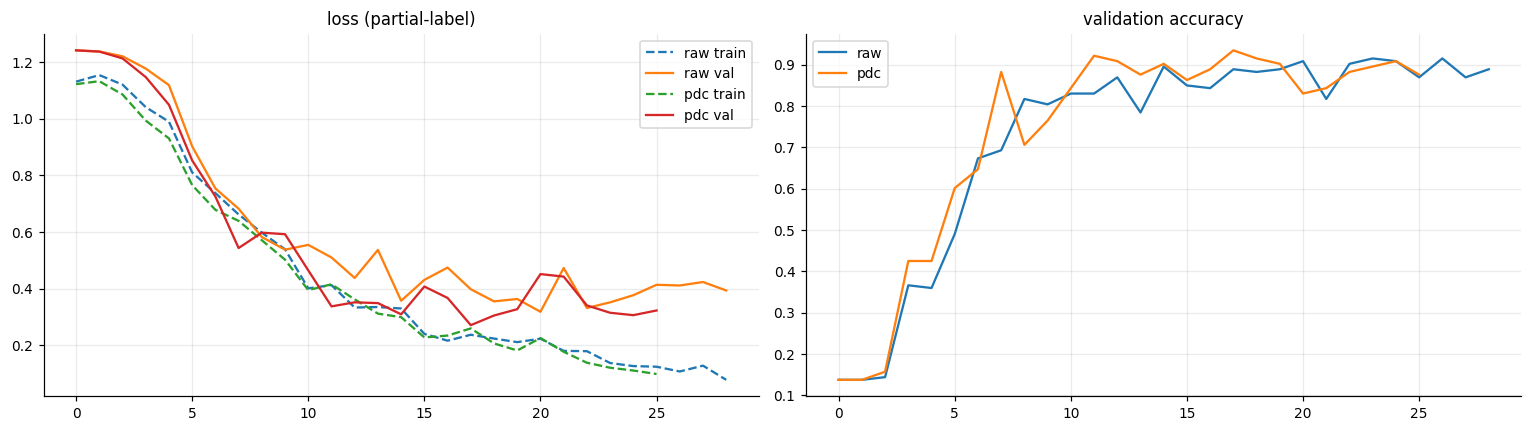

In [20]:
# E3 - learning curves
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for v in VARIANTS:
    h = pd.read_csv(f'{CKPT}/{v}/history.csv')
    ax[0].plot(h.epoch, h.train_loss, '--', label=f'{v} train'); ax[0].plot(h.epoch, h.val_loss, label=f'{v} val')
    ax[1].plot(h.epoch, h.val_acc, label=v)
ax[0].set_title('loss (partial-label)'); ax[1].set_title('validation accuracy'); [a.legend() for a in ax]
plt.tight_layout(); plt.savefig(f'{FIG}/E3_learning_curves.png'); plt.show()

In [21]:
print(len(D['y']), 'samples')
print(pd.crosstab([D['variant'], D['split']], D['y']))
print(os.listdir(CKPT), [os.listdir(f'{CKPT}/{v}') for v in os.listdir(CKPT)])

3586 samples
col_0         -2   -1    0    1    2    3
row_0 row_1                              
pdc   test    26   56   58   41   20   57
      train  162  230  333  242  118  231
      val     27   39   59   46   21   27
raw   test    26   56   58   41   20   57
      train  162  230  333  242  118  231
      val     27   39   59   46   21   27
['raw', 'pdc'] [['epoch_13.pt', 'epoch_20.pt', 'epoch_22.pt', 'epoch_01.pt', 'epoch_24.pt', 'epoch_27.pt', 'epoch_06.pt', 'epoch_09.pt', 'epoch_05.pt', 'epoch_16.pt', 'epoch_18.pt', 'epoch_02.pt', 'epoch_08.pt', 'epoch_19.pt', 'epoch_23.pt', 'last.pt', 'history.csv', 'epoch_14.pt', 'epoch_07.pt', 'epoch_03.pt', 'epoch_21.pt', 'epoch_10.pt', 'epoch_04.pt', 'epoch_15.pt', 'epoch_11.pt', 'epoch_28.pt', 'epoch_12.pt', 'best.pt', 'epoch_26.pt', 'epoch_25.pt', 'epoch_17.pt', 'epoch_00.pt'], ['epoch_13.pt', 'epoch_20.pt', 'epoch_22.pt', 'epoch_01.pt', 'epoch_24.pt', 'epoch_06.pt', 'epoch_09.pt', 'epoch_05.pt', 'epoch_16.pt', 'epoch_18.pt', 'epoch_02.

In [22]:
# F1 - calibrate, evaluate on UNSEEN test stars, export models
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix
CL = ['planet', 'eclipsing_binary', 'blend', 'other']
results = {}
for v in VARIANTS:
    s = torch.load(f'{CKPT}/{v}/best.pt', map_location=DEVICE, weights_only=False)
    model = AstroNetPlus().to(DEVICE); model.load_state_dict(s['model']); scaler = Standardizer.from_state(s['scaler'])
    va, te = select(v, 'val'), select(v, 'test')
    lv = logits(model, va, scaler); full = va['y'] >= 0
    T = TemperatureScaler().fit(lv[full], va['y'][full]) if full.sum() > 20 else TemperatureScaler()
    P = T(logits(model, te, scaler)); r = dict(best_epoch=int(s['epoch']), temperature=round(T.T, 3), n_test=len(te['y']))
    real = te['kind'] == 'real'; yb = (te['y'][real] == 0).astype(int)
    if real.any() and len(set(yb)) == 2:
        r.update(roc_auc=roc_auc_score(yb, P[real, 0]), pr_auc=average_precision_score(yb, P[real, 0]),
                 planet_recall=float((P[real, 0][yb == 1] >= .5).mean()), fp_rejected=float((P[real, 0][yb == 0] < .5).mean()))
    sim = te['kind'] == 'sim'
    if sim.any():
        r['sim_4class_acc'] = float((P[sim].argmax(1) == te['y'][sim]).mean())
        r['cm'] = confusion_matrix(te['y'][sim], P[sim].argmax(1), labels=range(4)).tolist()
    results[v] = r
    torch.save(model.state_dict(), f'{MODELS}/model_{v}.pt')
    json.dump(dict(scaler=scaler.state(), temperature=T.T, history=s['history']), open(f'{MODELS}/model_{v}.json', 'w'))
json.dump(results, open(f'{MODELS}/metrics.json', 'w'), indent=2, default=float)
pd.DataFrame({v: {k: x for k, x in r.items() if k != 'cm'} for v, r in results.items()})

,raw,pdc
best_epoch,20.000000,17.000000
temperature,1.132000,0.876000
n_test,202.000000,202.000000
roc_auc,0.789044,0.877622
pr_auc,0.802144,0.879234
planet_recall,0.696970,0.848485
fp_rejected,0.730769,0.769231
sim_4class_acc,0.916084,0.916084


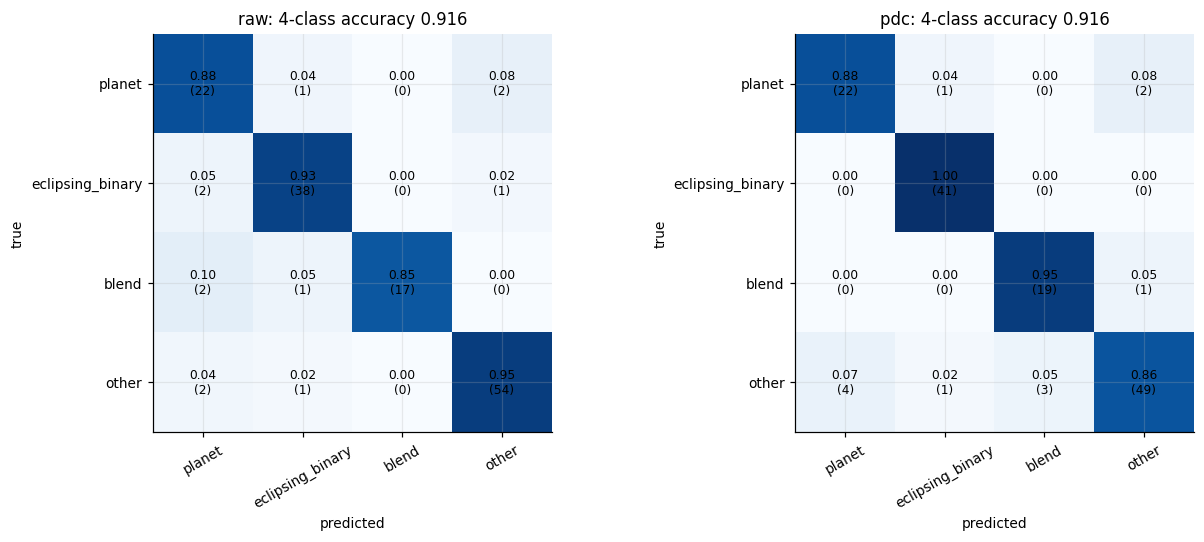

In [23]:
# F2 - confusion matrices: raw (ours) vs pdc (NASA)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, v in zip(ax, VARIANTS):
    if 'cm' not in results[v]: continue
    cm = np.array(results[v]['cm']); cn = cm / cm.sum(1, keepdims=True).clip(1)
    a.imshow(cn, cmap='Blues', vmin=0, vmax=1)
    for i in range(4):
        for j in range(4): a.text(j, i, f'{cn[i,j]:.2f}\n({cm[i,j]})', ha='center', va='center', fontsize=8)
    a.set_xticks(range(4), CL, rotation=30); a.set_yticks(range(4), CL); a.set_xlabel('predicted'); a.set_ylabel('true')
    a.set_title(f'{v}: 4-class accuracy {results[v]["sim_4class_acc"]:.3f}')
plt.tight_layout(); plt.savefig(f'{FIG}/F2_confusion.png'); plt.show()

In [24]:
# F3 - one zip with models + figures + metrics (easy download from the Output tab)
with zipfile.ZipFile(f'{OUT}/astrodetect_results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in (MODELS, FIG):
        for f in glob.glob(f'{folder}/*'): z.write(f, os.path.relpath(f, OUT))
    for v in VARIANTS:
        z.write(f'{CKPT}/{v}/history.csv', f'checkpoints/{v}/history.csv')
    if os.path.exists(f'{OUT}/recovery_all.csv'): z.write(f'{OUT}/recovery_all.csv', 'recovery_all.csv')
print('saved', f'{OUT}/astrodetect_results.zip', f'{os.path.getsize(f"{OUT}/astrodetect_results.zip")/1e6:.1f} MB')
print(sorted(os.listdir(FIG)))

saved /kaggle/working/astrodetect_results.zip 3.8 MB
['B1_dataset_overview.png', 'C10_significance.png', 'C2_raw_file_contents.png', 'C3_clean_crowding_stitch.png', 'C4_detrending.png', 'C5_bls_search.png', 'C6_transit_fit.png', 'C7_vetting.png', 'C8_model_inputs.png', 'C9_simulated_classes.png', 'D2_training_set.png', 'E3_learning_curves.png', 'F2_confusion.png']
